In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/digit-recognizer/sample_submission.csv
/kaggle/input/competitions/digit-recognizer/train.csv
/kaggle/input/competitions/digit-recognizer/test.csv


In [2]:
import numpy as np
import pandas as pd

import torch
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import transforms

# VAE

In [3]:
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch import optim
import torch.nn.functional as F

#하이퍼 파라미터 설정
input_dim=784  #image size=28*28
hidden_dim=200  #신경망 중간층의 차원 수
latent_dim=20   #잠재변수 z의 차원 수
epochs=30
learning_rate=3e-4
batch_size=32

class Encoder(nn.Module):
  def __init__(self, input_dim, hidden_dim, latent_dim):
    super().__init__()
    self.linear=nn.Linear(input_dim, hidden_dim)
    self.linear_mu=nn.Linear(hidden_dim, latent_dim)
    self.linear_logvar=nn.Linear(hidden_dim, latent_dim)

  def forward(self, x):
    h=self.linear(x)
    h=F.relu(h)
    mu=self.linear_mu(h)
    logvar=self.linear_logvar(h)
    sigma=torch.exp(0.5*logvar)
    return mu, sigma


class Decoder(nn.Module):
  def __init__(self, latent_dim, hidden_dim, output_dim):
    super().__init__()
    self.linear1=nn.Linear(latent_dim, hidden_dim)
    self.linear2=nn.Linear(hidden_dim, output_dim)

  def forward(self, z):
    h=self.linear1(z)
    h=F.relu(h)
    h=self.linear2(h)
    x_hat=F.sigmoid(h)   #MNIST 데이터 정규화 사이즈에 맞추기
    return x_hat

In [4]:
def reparameterize(mu, sigma):   #parameter에는 등록 안됨(nn상속 안받음), require_grads는 true(역전파 흘린다.)
  eps=torch.randn_like(sigma)
  z=mu+eps*sigma
  return z


class VAE(nn.Module):
  def __init__(self, input_dim, hidden_dim, latent_dim):
    super().__init__()
    self.encoder=Encoder(input_dim, hidden_dim, latent_dim)
    self.decoder=Decoder(latent_dim, hidden_dim, input_dim)

  def get_loss(self,x):
    mu, sigma=self.encoder(x)
    z=reparameterize(mu, sigma)
    x_hat=self.decoder(z)

    batch_size=len(x)
    L1=F.mse_loss(x_hat, x, reduction='sum')
    L2=-torch.sum(1+torch.log(sigma**2)-mu**2-sigma**2)
    return (L1+L2)/batch_size

## 데이터셋 생성

In [5]:
train_df=pd.read_csv('/kaggle/input/competitions/digit-recognizer/train.csv')
x_train=train_df.drop(['label'], axis=1, inplace=False).to_numpy().astype('uint8')  #ToTensor은 int64/32를 입력받으면 라벨로 인식해서 정규화 안함

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(torch.flatten)
])

In [6]:
x_train=x_train.reshape(-1,28,28)

class GetData(Dataset):
    def __init__(self, x_train, transform):
        self.x=x_train
        self.transform=transform


    def __len__(self):
        return len(self.x)


    def __getitem__(self, index):
        x=self.x[index]
        x=self.transform(x)
        return x


trainset=GetData(x_train, transform)
train_dataloader=DataLoader(trainset,batch_size=batch_size, shuffle=True, num_workers=2, drop_last=True)

## 학습

In [7]:
model=VAE(input_dim, hidden_dim, latent_dim)
optimizer=optim.Adam(model.parameters(), lr=learning_rate)
losses=[]

for epoch in range(epochs):
    loss_sum=0.0
    cnt=0

    for x in train_dataloader:
        loss=model.get_loss(x)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_sum+=loss.item()
        cnt+=1


    loss_avg=loss_sum/cnt
    losses.append(loss_avg)
    print(loss_avg)

56.96183079626502
46.54319443353793
44.69961595535278
43.39824049647262
42.52723640639608
41.81846168273833
41.4237684651119
40.971803618640436
40.77142311305535
40.62131913406093
40.35506556092239
40.26392696834192
40.109697940872934
39.96239800860242
39.8823103032461
39.7955932849791
39.65288487294825
39.59627871397065
39.48272598952782
39.4303922304293
39.35475403506582
39.30931076189367
39.2258175349817
39.19400199157436
39.14957822532189
39.10006481845205
39.039730406389005
38.98601679685639
38.95602740020287
38.92728727910577


## 새로운 이미지 생성

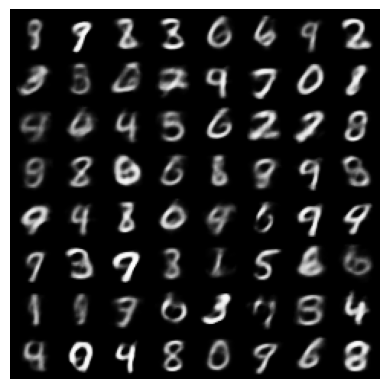

In [8]:
with torch.no_grad():
    sample_size=64
    z=torch.randn(sample_size, latent_dim)
    x=model.decoder(z)
    generated_img=x.view(sample_size, 1,28,28)

grid_img=torchvision.utils.make_grid(
    generated_img,
    nrow=8,
    padding=2,
    normalize=True
)

plt.imshow(grid_img.permute(1,2,0))
plt.axis('off')
plt.show()